# Example #6: Multiple junctions

SIS mixers often use more than one junction: e.g., twin-junction tuning circuits, where two junctions are separated by a short inductive line that tunes out their capacitance, or series arrays. QMix can simulate several junctions in one linear embedding network:

- ``qmix.circuit.MultiJunctionCircuit`` holds the embedding circuit: at each tone and harmonic, a *multi-port* Thevenin equivalent (a vector of open-circuit voltages and an impedance matrix that couples the junctions);
- ``qmix.harmonic_balance.harmonic_balance`` solves for the voltages across all junctions together, and ``qmix.qtcurrent.qtcurrent`` gives their tunneling currents;
- ``qmix.network.set_thevenin`` and ``qmix.network.impedance_matrix`` get these from an S-parameter network with one port per junction; and
- the small-signal analysis (``qmix.small_signal``) gives the conversion gain and noise temperature of the mixer: ``admittance_matrix`` and ``noise_matrix`` give one matrix per junction, and ``network_gain`` and ``network_output_noise`` solve the sideband network, including the thermal noise of a lossy embedding network.

This notebook simulates a twin-junction mixer at 230 GHz. In all arrays, the junction axis comes first and the junctions are numbered from 0 (``vt[j, f, p]``, ``zt[j, l, f, p]``, ``vj[j, f, p, i]``), so that ``vj[j]`` has the same shape as for one junction.

In [1]:
%matplotlib inline

import contextlib
import io

import numpy as np
import matplotlib.pyplot as plt
import scipy.constants as sc
from scipy.optimize import brentq

import qmix
from qmix.circuit import MultiJunctionCircuit
from qmix.harmonic_balance import harmonic_balance
from qmix.network import Network, impedance_matrix, set_thevenin, thevenin
from qmix.qtcurrent import qtcurrent
from qmix.small_signal import (admittance_matrix, noise_matrix, sideband_networks, sideband_impedances,
                               network_gain, network_output_noise)

# https://github.com/garrettj403/SciencePlots
import scienceplots
plt.style.use(['science', 'notebook'])

## The junctions

The junctions use the shape of the measured DC I-V curve from Example #3 (with the same smearing), but here each junction has a normal resistance of 20 $\Omega$ and a capacitance of 70 fF ($\omega R_n C \approx 2$ at 230 GHz). All values in the simulation are normalized to one junction's gap voltage and normal resistance (``rn``); junctions with different areas can be described with ``cct.area``, which scales their currents (and noise), and each junction can have its own response function (pass a list as ``resp``).

In [2]:
# Response function from the experimental DC I-V curve (Example #3)
def load(name):
    return np.genfromtxt('example-data/' + name, delimiter=',', skip_header=1)

with contextlib.redirect_stdout(io.StringIO()):
    dciv = qmix.exp.DCData(load('dciv.csv'), load('dcif.csv'), area=1.5, verbose=False)
resp = dciv.resp_smear

VGAP = dciv.vgap  # gap voltage, in V
RN = 20.          # normal resistance of each junction, in ohms
CAP = 70e-15      # capacitance of each junction, in F
TEMP = 4.2        # physical temperature, in K

print("Gap voltage: {:.3f} mV".format(VGAP * 1e3))

Gap voltage: 2.717 mV


## The twin-junction tuning circuit

The tuning circuit is built from ideal transmission lines with ``qmix.network``. Junction 0 sits at the end of a quarter-wave transformer from the RF port (a 35 $\Omega$ source, e.g., a waveguide probe), and junction 1 is connected to junction 0 by a short line ($Z_c = 8~\Omega$). The length of this line is chosen so that the admittance at junction 0 is real at 230 GHz: its inductance resonates with the capacitance of the two junctions. The transformer then matches the remaining (small) resistance to the source.

The junction capacitances are not part of the network: they are added in parallel with the junction ports (``cap`` argument) when the Thevenin equivalent is calculated.

In [3]:
F0 = 230e9    # design frequency, in Hz
R_S = 35.     # source impedance, in ohms
ZC = 8.       # characteristic impedance of the tuning line, in ohms
EPS = 4.      # effective permittivity of the lines


def line(freq, zc, length, loss=0.):
    "Transmission line (reference impedance zc at both ports); loss: attenuation relative to beta."
    beta = 2 * np.pi * freq * np.sqrt(EPS) / sc.c * (1 - 1j * loss)
    s = np.zeros((freq.size, 2, 2), dtype=complex)
    s[:, 0, 1] = s[:, 1, 0] = np.exp(-1j * beta * length)
    return Network(freq, s, zc)


def tee(freq, z0):
    "Ideal tee junction: three ports at one node."
    s = np.full((freq.size, 3, 3), 2 / 3, dtype=complex)
    s[:, [0, 1, 2], [0, 1, 2]] = -1 / 3
    return Network(freq, s, z0)


def y_junction(f):
    "Admittance of one junction in its normal state (Rn || C)."
    return 1 / RN + 2j * np.pi * f * CAP


def y_node(f, length):
    "Admittance at junction 0: junction 0 in parallel with the line to junction 1."
    beta = 2 * np.pi * f * np.sqrt(EPS) / sc.c
    zl, tan = 1 / y_junction(f), np.tan(beta * length)
    return y_junction(f) + (ZC + 1j * zl * tan) / (ZC * (zl + 1j * ZC * tan))


# Tuning line: the admittance at junction 0 is real at F0
wavelength = sc.c / np.sqrt(EPS) / F0
length = brentq(lambda l: y_node(F0, l).imag, 1e-3 * wavelength, 0.24 * wavelength)
r_node = 1 / y_node(F0, length).real
z_xfmr = np.sqrt(R_S * r_node)  # quarter-wave transformer
print("Tuning line: {:.1f} um ({:.3f} wavelengths)".format(length * 1e6, length / wavelength))
print("Resistance at junction 0: {:.2f} ohms -> transformer: {:.2f} ohms".format(r_node, z_xfmr))


def rf_network(freq, loss=0.):
    "RF circuit with ports: 1 = RF input, 2 = junction 0, 3 = junction 1."
    net = line(freq, z_xfmr, wavelength / 4, loss).connect(2, tee(freq, z_xfmr), 1)  # RF, J0, tee
    net = net.connect(3, line(freq, ZC, length, loss), 1)                           # RF, J0, J1
    return net.renormalize(np.array([R_S, z_xfmr, ZC]))


freq_rf = np.linspace(150e9, 320e9, 341)
rf = rf_network(freq_rf)
PORT_RF, PORTS_J = 1, [2, 3]

Tuning line: 92.4 um (0.142 wavelengths)
Resistance at junction 0: 1.76 ohms -> transformer: 7.86 ohms


``qmix.network.thevenin`` with a list of junction ports gives the multi-port Thevenin equivalent: the open-circuit voltages at the junction ports for a source with a given available power at the RF port, and the impedance matrix of the junction ports (with the junction capacitances in parallel). With the junctions in their normal state ($R_n$), the power that each of them absorbs follows from $V_J = (1 + Z_T / R_n)^{-1} V_T$. Most of the power goes into junction 1, at the end of the tuning line.

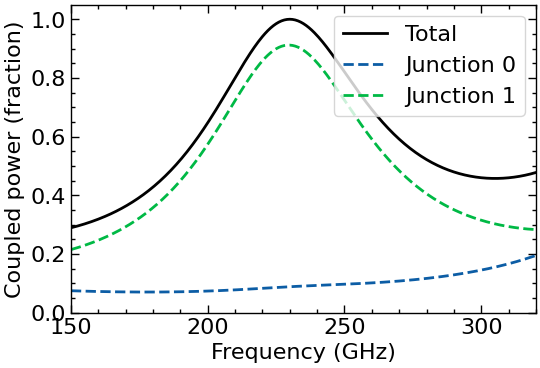

In [4]:
power = 1e-9  # available power, in W (any value: the coupling is linear here)
vt, zt = thevenin(rf, freq_rf, PORTS_J, PORT_RF, power=power, cap=CAP)
vj_normal = np.linalg.solve(np.eye(2) + zt / RN, vt[..., None])[..., 0]
coupling = np.abs(vj_normal) ** 2 / (2 * RN) / power

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(freq_rf / 1e9, coupling.sum(axis=1), 'k', label='Total')
ax.plot(freq_rf / 1e9, coupling[:, 0], 'C0--', label='Junction 0')
ax.plot(freq_rf / 1e9, coupling[:, 1], 'C1--', label='Junction 1')
ax.set(xlabel='Frequency (GHz)', ylabel='Coupled power (fraction)', xlim=[150, 320], ylim=[0, 1.05])
ax.legend(frameon=True)
plt.show()

## Pumping the junctions with the LO

``set_thevenin`` puts the Thevenin equivalent into a ``MultiJunctionCircuit`` (normalized), here for an LO at 230 GHz with an available power of 60 nW at the RF port. ``harmonic_balance`` then solves for the voltages across both junctions. Each junction is voltage biased: ``cct.vb[j]`` is the DC bias voltage of junction ``j`` (assigning a 1-D array, as here, biases both junctions at the same voltage).

In [5]:
P_LO = 60e-9  # LO power, in W

cct = MultiJunctionCircuit(2, 1, 1, vb_min=0, vb_max=2, vb_npts=201, vgap=VGAP, rn=RN)
cct.freq[1] = F0 / cct.fgap
set_thevenin(cct, rf, f=1, p=1, port=PORTS_J, source_port=PORT_RF, power=P_LO, cap=CAP)

print("Thevenin voltages:\n", cct.vt[:, 1, 1].round(3))
print("Thevenin impedance matrix:\n", cct.zt[:, :, 1, 1].round(3))

vj = harmonic_balance(cct, resp, num_b=15, stop_rerror=1e-8, max_it=50, verbose=False)
idc = qtcurrent(vj, cct, resp, 0., verbose=False)  # DC current of each junction, idc[j, i]

Thevenin voltages:
 [-0.   -0.j -1.194-0.j]
Thevenin impedance matrix:
 [[0.   -0.j    0.   -0.311j]
 [0.   -0.311j 1.097+0.j   ]]


The off-diagonal impedance couples the junctions. In the Thevenin equivalent, junction 1 is replaced by its capacitance alone, which resonates with the tuning line: this shorts the node of junction 0, so its open-circuit voltage and its own impedance are (nearly) zero. Junction 0 is only pumped through its coupling to junction 1.

The two junctions are pumped differently: junction 1 has a higher drive level ($\alpha = |V_{J}| / V_{ph}$), and its photon steps are more pronounced.

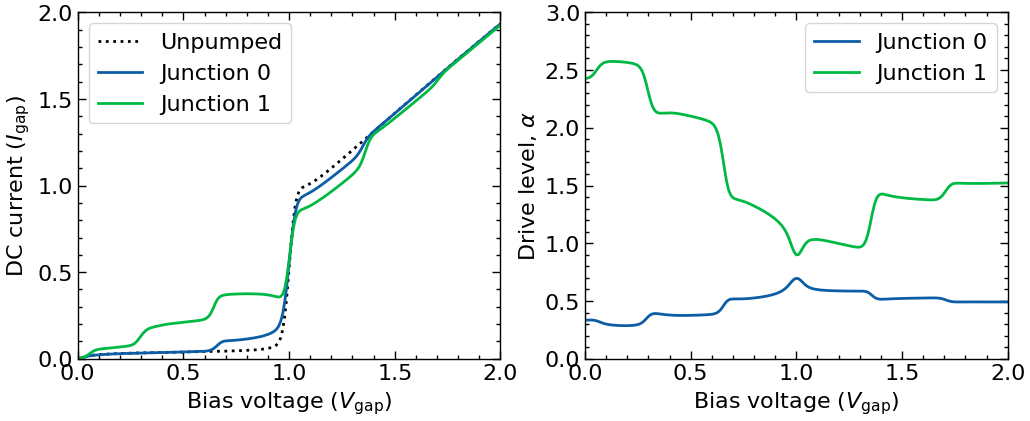

In [6]:
vb = cct.vb[0]
vph = cct.freq[1]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.plot(vb, resp.idc(vb), 'k:', label='Unpumped')
for j in range(2):
    ax1.plot(vb, idc[j], 'C{}'.format(j), label='Junction {}'.format(j))
ax1.set(xlabel=r'Bias voltage ($V_\mathrm{gap}$)', ylabel=r'DC current ($I_\mathrm{gap}$)', xlim=[0, 2], ylim=[0, 2])
ax1.legend(frameon=True)
for j in range(2):
    ax2.plot(vb, np.abs(vj[j, 1, 1]) / vph, 'C{}'.format(j), label='Junction {}'.format(j))
ax2.set(xlabel=r'Bias voltage ($V_\mathrm{gap}$)', ylabel=r'Drive level, $\alpha$', xlim=[0, 2], ylim=[0, 3])
ax2.legend(frameon=True)
plt.show()

## Small-signal analysis: gain and noise

For the small-signal analysis (Tucker theory), the junctions are coupled by the embedding network at every sideband (the IF, USB and LSB here). ``admittance_matrix`` and ``noise_matrix`` give the conversion admittance matrix and the current noise correlation matrix of each junction (``y[j, m, n, i]`` for sidebands $m, n$), and the network at each sideband is described by its impedance matrix over the junction ports and one *external* port: the RF port at the USB and LSB, and the IF port at the IF. ``qmix.network.impedance_matrix`` gives this from the S-parameters (with the junction capacitances), and ``sideband_networks`` collects them in the order used by ``qmix.small_signal`` (complex conjugates at the LSB). ``z_ext`` holds the impedances that terminate the external ports: the source impedance at the RF sidebands and the IF load at the IF.

At the IF (5 GHz), the tuning line is electrically short, so the junctions are connected in parallel to a 50 $\Omega$ IF load. The IF circuit is a tee with the IF port, junction 0, and the tuning line to junction 1.

In [7]:
F_IF = 5e9   # IF frequency, in Hz
R_IF = 50.   # IF load, in ohms

freq_if = np.linspace(1e9, 20e9, 39)
if_circuit = tee(freq_if, R_IF).connect(3, line(freq_if, ZC, length), 1)  # ports: IF, J0, J1
PORT_IF = 1

f_lo, f_if = cct.freq[1], F_IF / cct.fgap
y = admittance_matrix(vj, cct, resp, f_if, num_sb=1, num_b=15)
h = noise_matrix(vj, cct, resp, f_if, TEMP, num_sb=1, num_b=15)
print("Admittance matrices:", y.shape, "(junction, sideband, sideband, bias voltage)")

# Embedding networks: junction ports + the external port, normalized to Rn
caps = [CAP, CAP, 0.]
z_usb = impedance_matrix(rf, F0 + F_IF, PORTS_J + [PORT_RF], cap=caps) / RN
z_lsb = impedance_matrix(rf, F0 - F_IF, PORTS_J + [PORT_RF], cap=caps) / RN
z_if = impedance_matrix(if_circuit, F_IF, PORTS_J + [PORT_IF], cap=caps) / RN
z_net = sideband_networks(z_if, z_usb, z_lsb)
z_ext = sideband_impedances(R_IF / RN, R_S / RN, R_S / RN)

Admittance matrices: (2, 3, 3, 201) (junction, sideband, sideband, bias voltage)


``network_gain`` gives the transducer gain from the source at an RF sideband to the IF load, and ``network_output_noise`` the noise delivered to the IF load (as a temperature). The noise sources are the shot noise of the junctions (uncorrelated between the junctions), the embedding network (``temp``; a lossless network has no noise of its own) and the terminations of the external ports (``temp_ext``), all with Callen-Welton temperatures. For the double-sideband (DSB) noise temperature of the mixer, the noise of both RF inputs and of the IF load is excluded, and the output noise is divided by the sum of the USB and LSB gains.

Best bias: 0.740 Vgap (2.01 mV)
DSB gain:  4.65 dB (USB 1.51 dB, LSB 1.76 dB)
DSB noise temperature: 4.4 K


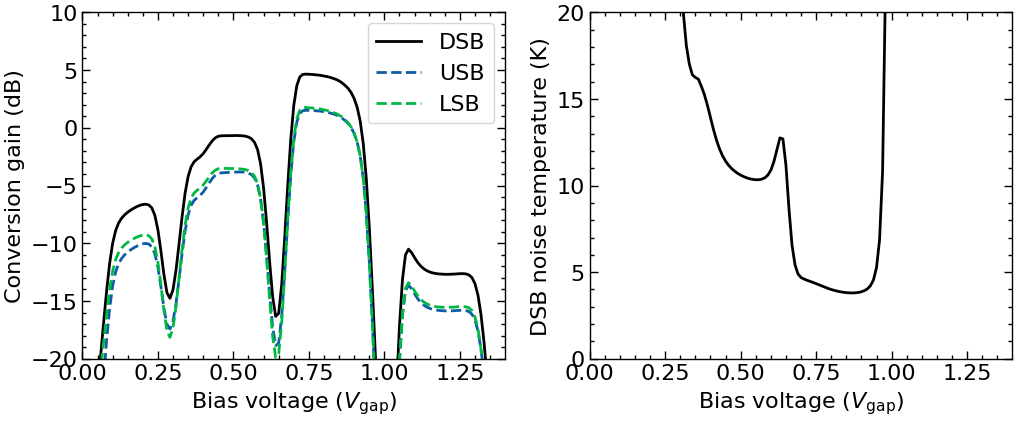

In [8]:
g_usb = network_gain(y, z_net, z_ext, 1)
g_lsb = network_gain(y, z_net, z_ext, -1)
g_dsb = g_usb + g_lsb
t_out = network_output_noise(y, h, z_net, z_ext, VGAP, f_lo, f_if, temp=TEMP, temp_ext=TEMP, exclude=[-1, 0, 1])
tn_dsb = t_out / g_dsb

best = np.argmax(g_dsb)
print("Best bias: {:.3f} Vgap ({:.2f} mV)".format(vb[best], vb[best] * VGAP * 1e3))
print("DSB gain:  {:.2f} dB (USB {:.2f} dB, LSB {:.2f} dB)".format(
      10 * np.log10(g_dsb[best]), 10 * np.log10(g_usb[best]), 10 * np.log10(g_lsb[best])))
print("DSB noise temperature: {:.1f} K".format(tn_dsb[best]))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.plot(vb, 10 * np.log10(g_dsb), 'k', label='DSB')
ax1.plot(vb, 10 * np.log10(g_usb), 'C0--', label='USB')
ax1.plot(vb, 10 * np.log10(g_lsb), 'C1--', label='LSB')
ax1.set(xlabel=r'Bias voltage ($V_\mathrm{gap}$)', ylabel='Conversion gain (dB)', xlim=[0, 1.4], ylim=[-20, 10])
ax1.legend(frameon=True)
ax2.plot(vb, tn_dsb, 'k')
ax2.set(xlabel=r'Bias voltage ($V_\mathrm{gap}$)', ylabel='DSB noise temperature (K)', xlim=[0, 1.4], ylim=[0, 20])
plt.show()

This is the noise added by the mixer itself (with the noise of the RF inputs and of the IF load excluded). Since the tuning circuit is lossless, it is the shot noise of the junctions, coupled to the IF through the network. The receiver noise would also include the noise of the optics and of the IF amplifier.

## Check: multi-tone simulation

The small-signal analysis assumes that the RF signal is weak. It can be checked with a multi-tone harmonic balance of both junctions with four tones (LO, USB, LSB and IF), a weak RF signal at the USB, and the IF load. ``set_thevenin`` without a ``source_port`` gives the Thevenin impedance matrix for the tones without a source (the LSB and the IF). The power in the IF load follows from the junction currents at the IF, $I_L = \sum_j Z_{x j} I_j / (Z_{xx} + R_\mathrm{IF})$, where $x$ is the IF port.

Note that at a low IF, the RF signal has to be *very* weak: the drive level of the IF tone, $|V_\mathrm{IF}| / V_\mathrm{ph,IF}$, is large even for a small IF voltage, since the IF photon voltage is small (0.007 $V_\mathrm{gap}$ here). With 1 pW instead of 0.1 fW, the multi-tone gain differs from the small-signal gain by ~0.5%.

In [9]:
P_RF = 1e-16  # RF power, in W

vb_check = np.linspace(0.6, 1.0, 9)
cct4 = MultiJunctionCircuit(2, 4, 1, vb_npts=vb_check.size, vgap=VGAP, rn=RN)
cct4.vb = vb_check
cct4.freq[1:] = np.array([F0, F0 + F_IF, F0 - F_IF, F_IF]) / cct4.fgap
set_thevenin(cct4, rf, f=1, port=PORTS_J, source_port=PORT_RF, power=P_LO, cap=CAP)  # LO
set_thevenin(cct4, rf, f=2, port=PORTS_J, source_port=PORT_RF, power=P_RF, cap=CAP)  # USB
set_thevenin(cct4, rf, f=3, port=PORTS_J, cap=CAP)                                   # LSB
set_thevenin(cct4, if_circuit, f=4, port=PORTS_J, cap=CAP)                           # IF

num_b = (15, 3, 3, 3)
vj4 = harmonic_balance(cct4, resp, num_b, stop_rerror=1e-8, max_it=50, verbose=False, warm_start=True)
i_if = qtcurrent(vj4, cct4, resp, cct4.freq[4], num_b, verbose=False) * cct4.igap  # in A

z_if_ohm = impedance_matrix(if_circuit, F_IF, PORTS_J + [PORT_IF], cap=caps)
i_load = z_if_ohm[2, :2] @ i_if / (z_if_ohm[2, 2] + R_IF)
g_usb_multitone = 0.5 * np.abs(i_load) ** 2 * R_IF / P_RF

g_usb_small_signal = np.interp(vb_check, vb, g_usb)
print("Bias     Small-signal  Multi-tone  Rel. difference")
for v, g1, g2 in zip(vb_check, g_usb_small_signal, g_usb_multitone):
    print("{:.3f}    {:10.6f}  {:10.6f}  {:9.1e}".format(v, g1, g2, g2 / g1 - 1))

Bias     Small-signal  Multi-tone  Rel. difference
0.600      0.151595    0.151596    4.3e-06
0.650      0.013690    0.013690    4.0e-05
0.700      0.756183    0.756182   -9.1e-07
0.750      1.414936    1.414932   -2.4e-06
0.800      1.378269    1.378265   -2.8e-06
0.850      1.258928    1.258924   -3.2e-06
0.900      0.892706    0.892702   -3.4e-06
0.950      0.069976    0.069976    8.6e-06
1.000      0.000074    0.000074    6.2e-04


The two agree to a few parts in 1e6 where the gain is large (the remaining difference is the effect of the finite RF signal and of the truncated sums), and the relative difference only grows where the gain is small. The small-signal analysis is much faster: it needs the harmonic balance of the LO alone, and it gives the gain and noise at any IF without frequency rounding.

## A lossy tuning circuit

The embedding network can also be lossy. A passive network at a physical temperature $T$ has open-circuit noise voltages with the correlation matrix $2 k T_\mathrm{CW} (Z + Z^\dagger)$ per unit bandwidth (Twiss' theorem, with the Callen-Welton temperature $T_\mathrm{CW}$), which ``network_output_noise`` includes when ``temp`` is given. Here, the lines have an attenuation of 2% of their propagation constant (e.g., a normal-metal tuning circuit). The loss reduces the gain and adds the thermal noise of the network (the difference between the solid and the dashed red lines). Even without the network's own noise, the noise temperature is higher, since the noise of the junctions is referred to the input through a lower gain. At 230 GHz, the Callen-Welton temperature of the network at 4.2 K is ~6.4 K, i.e., its zero-point fluctuations are a large part of its noise.

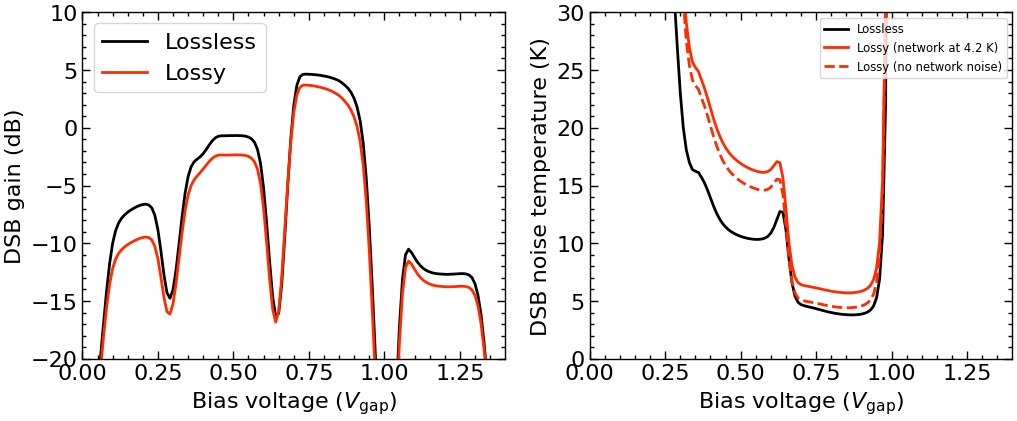

Lossy circuit at 0.740 Vgap: DSB gain 3.70 dB, noise 6.2 K (4.9 K without the network's noise)


In [10]:
def mixer(network, temp):
    "DSB gain and noise temperature of the mixer with this RF network (same LO power and bias)."
    c = MultiJunctionCircuit(2, 1, 1, vb_min=0, vb_max=2, vb_npts=201, vgap=VGAP, rn=RN)
    c.freq[1] = F0 / c.fgap
    set_thevenin(c, network, port=PORTS_J, source_port=PORT_RF, power=P_LO, cap=CAP)
    v = harmonic_balance(c, resp, num_b=15, stop_rerror=1e-8, max_it=50, verbose=False)
    y_ = admittance_matrix(v, c, resp, f_if, num_sb=1, num_b=15)
    h_ = noise_matrix(v, c, resp, f_if, TEMP, num_sb=1, num_b=15)
    z_net_ = sideband_networks(z_if, impedance_matrix(network, F0 + F_IF, PORTS_J + [PORT_RF], cap=caps) / RN,
                               impedance_matrix(network, F0 - F_IF, PORTS_J + [PORT_RF], cap=caps) / RN)
    g = network_gain(y_, z_net_, z_ext, 1) + network_gain(y_, z_net_, z_ext, -1)
    t = network_output_noise(y_, h_, z_net_, z_ext, VGAP, f_lo, f_if, temp=temp, temp_ext=TEMP, exclude=[-1, 0, 1])
    return g, t / g


lossy = rf_network(freq_rf, loss=0.02)
g_lossy, tn_lossy = mixer(lossy, TEMP)
_, tn_lossy_no_network_noise = mixer(lossy, None)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.plot(vb, 10 * np.log10(g_dsb), 'k', label='Lossless')
ax1.plot(vb, 10 * np.log10(g_lossy), 'C3', label='Lossy')
ax1.set(xlabel=r'Bias voltage ($V_\mathrm{gap}$)', ylabel='DSB gain (dB)', xlim=[0, 1.4], ylim=[-20, 10])
ax1.legend(frameon=True)
ax2.plot(vb, tn_dsb, 'k', label='Lossless')
ax2.plot(vb, tn_lossy, 'C3', label='Lossy (network at 4.2 K)')
ax2.plot(vb, tn_lossy_no_network_noise, 'C3--', label='Lossy (no network noise)')
ax2.set(xlabel=r'Bias voltage ($V_\mathrm{gap}$)', ylabel='DSB noise temperature (K)', xlim=[0, 1.4], ylim=[0, 30])
ax2.legend(frameon=True, loc='upper right', fontsize='small')
plt.show()

i = np.argmax(g_lossy)
print("Lossy circuit at {:.3f} Vgap: DSB gain {:.2f} dB, noise {:.1f} K ({:.1f} K without the network's noise)".format(
      vb[i], 10 * np.log10(g_lossy[i]), tn_lossy[i], tn_lossy_no_network_noise[i]))

## Summary

- ``MultiJunctionCircuit(num_j, num_f, num_p)``: multi-port Thevenin equivalent at each tone and harmonic (``vt[j, f, p]``, ``zt[j, l, f, p]``), bias voltage per junction (``vb[j, i]``), relative areas (``area``).
- ``harmonic_balance`` and ``qtcurrent``: as for one junction, with the junction axis first (``vj[j, f, p, i]``); ``resp`` can be a list (one per junction).
- ``qmix.network``: ``thevenin`` / ``set_thevenin`` with a list of junction ports, and ``impedance_matrix`` for the embedding networks of the small-signal analysis.
- ``qmix.small_signal``: ``admittance_matrix`` and ``noise_matrix`` (one per junction), ``sideband_networks``, ``network_gain``, ``network_output_noise`` and ``network_noise_temperature``. These also work for one junction behind a lossy network.

All junctions share one gap voltage and normal resistance (junctions of the same materials), and each junction is voltage biased.